# House Advisor Agent

This is an AI agent project.

The file is Melbourne house sales: suburb, type, rooms, bathrooms, price and distance to the center. I will plot price and room counts, keep 2500 sales, and store each one as a short text in Chroma. Chroma embeds that text with a small embedding model and returns the closest sales. That embedding model is the deep learning part. OpenRouter then writes the answer from those rows only. The API key is read from AIAgents/.env.


In [1]:
import kagglehub

path = kagglehub.dataset_download("dansbecker/melbourne-housing-snapshot")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\dansbecker\melbourne-housing-snapshot\versions\5


In [2]:
import os
import glob
import pandas as pd

csv_path = glob.glob(os.path.join(path, "**", "melb_data.csv"), recursive=True)[0]
df = pd.read_csv(csv_path)
df["type_name"] = df["Type"].map({"h": "house", "u": "unit", "t": "townhouse"})
df.head()


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,type_name
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0,house
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0,house
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0,house
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0,house
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0,house


In [3]:
print(df.shape)
print(df["type_name"].value_counts())
df[["Rooms", "Bathroom", "Price", "Distance"]].describe()


(13580, 22)
type_name
house        9449
unit         3017
townhouse    1114
Name: count, dtype: int64


,Rooms,Bathroom,Price,Distance
count,13580.000000,13580.000000,1.358000e+04,13580.000000
mean,2.937997,1.534242,1.075684e+06,10.137776
std,0.955748,0.691712,6.393107e+05,5.868725
min,1.000000,0.000000,8.500000e+04,0.000000
25%,2.000000,1.000000,6.500000e+05,6.100000
50%,3.000000,1.000000,9.030000e+05,9.200000
75%,3.000000,2.000000,1.330000e+06,13.000000
max,10.000000,8.000000,9.000000e+06,48.100000


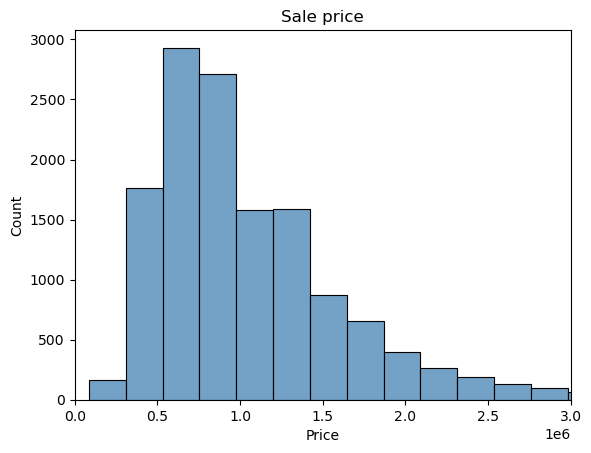

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["Price"], bins=40, color="steelblue")
plt.xlim(0, 3000000)
plt.title("Sale price")
plt.show()


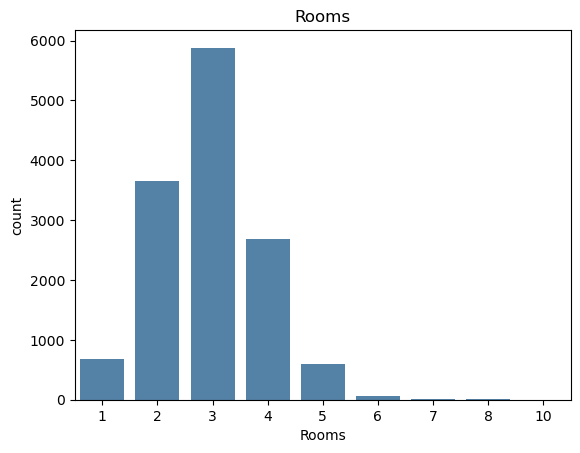

In [5]:
sns.countplot(data=df, x="Rooms", color="steelblue")
plt.title("Rooms")
plt.show()


In [6]:
df = df.dropna(subset=["Price", "Rooms", "Bathroom", "Distance", "Regionname", "type_name"])
df = df.sample(2500, random_state=42).reset_index(drop=True)
df["text"] = (
    df["Suburb"]
    + " | " + df["type_name"]
    + " | rooms " + df["Rooms"].astype(int).astype(str)
    + " | bathrooms " + df["Bathroom"].astype(int).astype(str)
    + " | price " + df["Price"].astype(int).astype(str)
    + " | distance_km " + df["Distance"].astype(str)
    + " | " + df["Regionname"]
)
df["text"].head()


0    Brighton | house | rooms 3 | bathrooms 2 | pri...
1    West Melbourne | unit | rooms 2 | bathrooms 1 ...
2    St Kilda | unit | rooms 3 | bathrooms 1 | pric...
3    Pascoe Vale | townhouse | rooms 3 | bathrooms ...
4    South Kingsville | house | rooms 2 | bathrooms...
Name: text, dtype: object

In [7]:
import chromadb

col = chromadb.Client().get_or_create_collection("houses")
col.add(ids=df.index.astype(str).tolist(), documents=df["text"].tolist())
print(col.count())


2500


In [8]:
query = "A 2 bedroom unit under 700000 close to the city center"
found = col.query(query_texts=[query], n_results=5)
print("\n\n".join(found["documents"][0]))


Flemington | unit | rooms 2 | bathrooms 1 | price 425000 | distance_km 4.4 | Northern Metropolitan

Richmond | unit | rooms 2 | bathrooms 1 | price 717000 | distance_km 2.4 | Northern Metropolitan

Richmond | unit | rooms 2 | bathrooms 1 | price 660000 | distance_km 2.4 | Northern Metropolitan

Richmond | unit | rooms 2 | bathrooms 1 | price 760000 | distance_km 2.6 | Northern Metropolitan

Richmond | unit | rooms 2 | bathrooms 2 | price 630000 | distance_km 2.6 | Northern Metropolitan


# OpenRouter key

Write the key in `AIAgents/.env`, on the same line, right after the equals sign. Then run the next cell. It reads that file. The agent cells below use it.


In [9]:
from pathlib import Path

env_path = next(p for p in [Path("AIAgents/.env"), Path(".env")] if p.exists())
os.environ["OPENROUTER_API_KEY"] = env_path.read_text(encoding="utf-8").split("=", 1)[1].strip().strip('"').strip("'")
print("key loaded from", env_path)


key loaded from .env


In [10]:
import json
import requests
from IPython.display import Markdown

def house_agent(query):
    found = col.query(query_texts=[query], n_results=5)
    context = "\n".join(found["documents"][0])
    prompt = (
        "You are a house buyer advisor. Use ONLY the sales in the context. Prices are AUD.\n"
        "Format: ## Best matches then a bullet with suburb, type, rooms, price and distance.\n"
        "## Final pick with one sentence.\n\n"
        "Context:\n" + context + "\n\nBuyer:\n" + query
    )
    response = requests.post(
        url="https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": "Bearer " + os.environ["OPENROUTER_API_KEY"],
            "Content-Type": "application/json",
        },
        data=json.dumps({
            "model": "nvidia/nemotron-3-super-120b-a12b:free",
            "messages": [{"role": "user", "content": prompt}],
        }),
    )
    text = response.json()["choices"][0]["message"]["content"]
    return Markdown(text)

house_agent(query)


## Best matches
- Richmond, unit, 2 rooms, $660,000, 2.4 km  
- Richmond, unit, 2 rooms, $630,000, 2.6 km  
- Flemington, unit, 2 rooms, $425,000, 4.4 km  

## Final pick
The best match is the Richmond 2‑bedroom unit priced at $660,000, located just 2.4 km from the city centre.

In [11]:
house_agent("A family house with 4 rooms in the southern or eastern suburbs")


## Best matches
- South Yarra | house | rooms 4 | price 2667000 | distance_km 3.3
- Glen Iris | house | rooms 4 | price 1900000 | distance_km 9.2

## Final pick
The Glen Iris house offers 4 rooms at the lowest price among the matches.

# Conclusion

I plotted Melbourne sale prices and room counts, then indexed 2500 sales. Each document is suburb, type, rooms, bathrooms, price, distance and region. Chroma embeds that text and retrieves the five closest sales. That embedding step is the deep learning in this project. The agent sends only those five rows to OpenRouter. The chat model is nvidia/nemotron-3-super-120b-a12b:free. It writes the shortlist from that context. The key is read from AIAgents/.env. The collection lives in the kernel session, so the index cell has to run again after a restart.
